# Machine Learning Algorithms, Model Selection and Evaluation

## 📊 Linear Regression and Regression Metrics

In this exercise, we will explore linear regression using the same dataset. We will cover the following key steps:

1. **Model Training**: Fit a linear regression model to the training data.
2. **Prediction**: Use the trained model to make predictions on the test data.
3. **Evaluation**: Assess the model's performance using various regression metrics such as Mean Absolute Error (MAE), Mean Squared Error (MSE), and R-squared.



# 🔄 Prepare the Data

Reload `../../Excercise_data/L01/India_air_quality.csv` so you start with the original feature values.

- As in Exercise 01, treat exact duplicate rows as accidental copies and keep one copy.
- Keep rows with an observed `rspm` response. Do not impute the target.
- Use the numerical features. Apply the same fixed rule from Exercise 01 to exclude rows with impossible negative concentrations, keeping features and response aligned.
- Split into 70% training and 30% test data with `random_state=42`.
- Keep feature values unscaled and missing entries unfilled. Retain the numerical columns; do not select them using missing fractions from the full training set before CV.

The pipeline will learn imputation and scaling within each fold. The separately transformed arrays from Exercise 01 help you understand these steps, but are not the inputs to cross-validation.

In [7]:
# ADD YOUR CODE HERE -- You can create new markdown and code cells
# ADD YOUR CODE HERE -- You can create new markdown and code cells
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
df = pd.read_csv('../../Excercise_data/L01/India_air_quality.csv', index_col=0)
df.drop_duplicates(inplace=True)
df = df[~df['rspm'].isnull()]
df = df[df.select_dtypes(include=[np.number]).columns]
# df = df[(df >= 0).all(axis=1)]
X = df.drop(columns=['rspm'])
y = df['rspm']
# df
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

/tmp/ipykernel_596849/2765054306.py:7: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


# Modelling

Predict `rspm` using five-fold cross-validation on the training data, shuffled with a fixed seed.

Use one pipeline containing `SimpleImputer(strategy='median')`, `StandardScaler()` and `LinearRegression()`. Pass the unfilled numerical `X_train` and observed `y_train` to cross-validation.

- Report mean ± standard deviation of CV-MAE, CV-RMSE and CV-R².
- Which metric, MAE or RMSE, would you prioritise here, and why?

<details><summary>💡 Hint</summary>

Use `make_pipeline` from `sklearn.pipeline` to join the three steps. Use `KFold(n_splits=5, shuffle=True, random_state=42)` for reproducible folds.

Call `cross_val_score` with scoring='neg_mean_absolute_error', scoring='neg_root_mean_squared_error' and scoring='r2'. Change the sign of the MAE and RMSE scores before reporting them: scikit-learn's scoring convention makes larger scores better.

Each fold fits a fresh copy of the complete pipeline. Do not call `fit_transform` on the full training set before these calls.

</details>

In [10]:
# ADD YOUR CODE HERE -- You can create new markdown and code cells
from sklearn.model_selection import cross_val_score, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression

pipeline = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LinearRegression())
cv = KFold(n_splits=5, shuffle=True, random_state=42)

pipeline.fit(X_train, y_train)
scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring='neg_mean_absolute_error')

In [18]:
scores

array([-42.1095392 , -41.75853679, -41.70722794, -41.98396542,
       -41.93000004])

## Refit & Single Test Evaluation

Fit the chosen **pipeline** on the entire unfilled numerical training set, then use its predict method on the unfilled numerical test set. It applies the imputer and scaler learned from training data.

- Report test MAE, RMSE and R².
- Does test performance align with the CV estimate? Give one plausible reason for any gap.
- Do not use this test result to revise the model and then present the same test set as an independent final evaluation.

In [17]:
# ADD YOUR CODE HERE -- You can create new markdown and code cells
y_pred = pipeline.predict(X_test)
# MAE
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
mae = mean_absolute_error(y_test, y_pred)
# R2 Score
r2_score = r2_score(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred)**0.5
print(f'Mean Absolute Error: {mae}')
print(f'Root Mean Squared Error: {rmse}')
print(f'R2 Score: {r2_score}')

Mean Absolute Error: 41.910469671209846
Root Mean Squared Error: 60.47818058662713
R2 Score: 0.32145337372275806


# Visualizing the Regression Fit
plot a visual comparison between actual and predicted values for the test set.


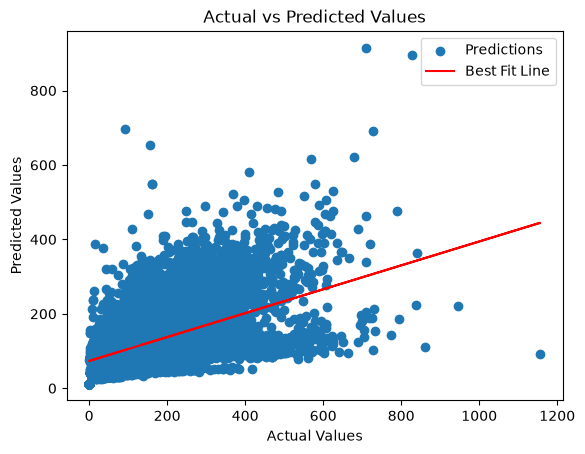

In [29]:
# ADD YOUR CODE HERE -- You can create new markdown and code cells
import matplotlib.pyplot as plt
import numpy as np

plt.scatter(y_test, y_pred, label = 'Predictions')

m, c = np.polyfit(y_test, y_pred, 1)
plt.plot(y_test, m*y_test + c, color='red', label = 'Best Fit Line')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted Values')
plt.legend()

# How Good Is Your Score?

Interpret your measured errors in the units of `rspm`. Are they small enough for the intended use?

<details><summary>💡 Discussion</summary>

Compare the error magnitude with the response values and the tolerance of the application. A gap between CV and test performance can reflect sampling variation or differences between observations. Weak performance may also reflect limited features or a relationship that a linear model describes poorly.

These are hypotheses to investigate using training data; the scores alone do not identify the cause. Categorical features were omitted in this introductory model and may provide useful information.

</details>

In [32]:
y_test.min(), y_test.max()

(np.float64(0.0), np.float64(1156.0))

In [33]:
y_test.describe()

count    92887.000000
mean       107.991909
std         73.419464
min          0.000000
25%         56.000000
50%         90.000000
75%        140.000000
max       1156.000000
Name: rspm, dtype: float64

# Save your results 
save `y_test` and `y_pred` in a csv file

In [37]:
# ADD YOUR CODE HERE -- You can create new markdown and code cells
df1 = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
df1.to_csv('predictions.csv', index=False)

# 🏁 Finished!

You have evaluated the complete preprocessing and modelling procedure using cross-validation, refitted it on the training set and interpreted one final test result. Validation and test observations must not determine fitted preprocessing.